### Elienai Simon Mier
#### 2027726
#### CA1
#### GitHub: https://github.com/2026726-dotcom/Machine-Learning

#### Dataset:

This dataset is about student performance and some variables that may be important in their education progress. The dataset has attributes like demografic information, study habits, particition exrtracurricular, and academic outcomes. With this information we pretend to analyse their performace that can be used to improve the education in some way.

In [55]:
# Import libraries that might be needed

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import mglearn   ###Clustering
from cycler import cycler
from sklearn.model_selection import train_test_split, cross_val_score #OK
from sklearn import svm #OK
from sklearn import metrics #OK
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder

import warnings
warnings.filterwarnings('ignore') # We can suppress the warnings

In [2]:
##Read dataset from file no CSV

# Define column names
column_names = ["StudentID", "Age", "Gender", "Ethnicity", "ParentalEducation", "StudyTimeWeekly", "Absences", "Tutoring", "ParentalSupport","Extracurricular","Sports","Music","Volunteering","GPA","GradeClass"]

# Read the file while handling variable spacing and ensuring correct parsing of values
df = pd.read_csv(
    "dataset.data",            # File name
    sep = r',',                 # Handles multiple spaces as delimiters
    names = column_names,         # Assign column names
    na_values = "?"                # Convert '?' (missing values) to NaN (especially for horsepower)
)

# Display the first few rows
df

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001.0,17.0,1.0,0.0,2.0,19.833723,7.0,1.0,2.0,0.0,0.0,1.0,0.0,2.929196,2.0
1,1002.0,18.0,0.0,0.0,1.0,15.408756,0.0,0.0,1.0,0.0,0.0,0.0,0.0,3.042915,1.0
2,1003.0,15.0,0.0,2.0,3.0,4.210570,26.0,0.0,2.0,0.0,0.0,0.0,0.0,0.112602,4.0
3,1004.0,17.0,1.0,0.0,3.0,10.028829,14.0,0.0,3.0,1.0,0.0,0.0,0.0,2.054218,3.0
4,1005.0,17.0,1.0,0.0,2.0,4.672495,17.0,1.0,3.0,0.0,0.0,0.0,0.0,1.288061,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2387,3388.0,18.0,1.0,0.0,3.0,10.680555,2.0,0.0,4.0,1.0,0.0,0.0,0.0,3.455509,0.0
2388,3389.0,17.0,0.0,0.0,1.0,7.583217,4.0,1.0,4.0,0.0,1.0,0.0,0.0,3.279150,4.0
2389,3390.0,16.0,1.0,0.0,2.0,6.805500,20.0,0.0,2.0,0.0,0.0,0.0,1.0,1.142333,2.0
2390,3391.0,16.0,1.0,1.0,0.0,12.416653,17.0,0.0,2.0,0.0,1.0,1.0,0.0,1.803297,1.0


#### 1. Exploration dataset

In [4]:
#Read first five rows
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001.0,17.0,1.0,0.0,2.0,19.833723,7.0,1.0,2.0,0.0,0.0,1.0,0.0,2.929196,2.0
1,1002.0,18.0,0.0,0.0,1.0,15.408756,0.0,0.0,1.0,0.0,0.0,0.0,0.0,3.042915,1.0
2,1003.0,15.0,0.0,2.0,3.0,4.210570,26.0,0.0,2.0,0.0,0.0,0.0,0.0,0.112602,4.0
3,1004.0,17.0,1.0,0.0,3.0,10.028829,14.0,0.0,3.0,1.0,0.0,0.0,0.0,2.054218,3.0
4,1005.0,17.0,1.0,0.0,2.0,4.672495,17.0,1.0,3.0,0.0,0.0,0.0,0.0,1.288061,4.0


In [5]:
#Size of the dataset
df.shape

(2392, 15)

In [6]:
#Type of data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   float64
 1   Age                2392 non-null   float64
 2   Gender             2392 non-null   float64
 3   Ethnicity          2392 non-null   float64
 4   ParentalEducation  2392 non-null   float64
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   float64
 7   Tutoring           2392 non-null   float64
 8   ParentalSupport    2392 non-null   float64
 9   Extracurricular    2392 non-null   float64
 10  Sports             2392 non-null   float64
 11  Music              2392 non-null   float64
 12  Volunteering       2392 non-null   float64
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(15)
memory usage: 280.4 KB


In [7]:
#Null values
df.isnull().sum()

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64

### About the dataset

The dataset has 15 columns about students and features that can be affect their education. 
After an exploration, we have conclude that the column "StudentID" and "Ethnicity" are not important for this analysis.
In this context, the next step is remove those columns and continue with the aim.

### Aim

The aim of this analysis is obtain a machine learning model to analyse the many factores in education of students.
We will apply k-means and ML for more observations....

The Target is Grade Class, this means that it will be identify the Grade according to the features. We will use the next:
1. Supervised Learning to show the Grade Class (kNN Clasification)
2. Clustering
2. Linear Regression to predict their GPA
3. 



### Classification


In [14]:
#Classification using sklearn
##Normalise or split the dataset into test and training
#Let's see first the values of the data if they need or not to be normalised
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000




The dataset has not values out of scale, so it is not needed to normalise, we will procede to split the dataset



In [60]:
##Remove "StudentID" and "Ethnicity" these features are unique or not considered important to develop the model
df1 = df.drop(["StudentID"], axis=1)
df1


,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,17.0,1.0,0.0,2.0,19.833723,7.0,1.0,2.0,0.0,0.0,1.0,0.0,2.929196,2.0
1,18.0,0.0,0.0,1.0,15.408756,0.0,0.0,1.0,0.0,0.0,0.0,0.0,3.042915,1.0
2,15.0,0.0,2.0,3.0,4.210570,26.0,0.0,2.0,0.0,0.0,0.0,0.0,0.112602,4.0
3,17.0,1.0,0.0,3.0,10.028829,14.0,0.0,3.0,1.0,0.0,0.0,0.0,2.054218,3.0
4,17.0,1.0,0.0,2.0,4.672495,17.0,1.0,3.0,0.0,0.0,0.0,0.0,1.288061,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2387,18.0,1.0,0.0,3.0,10.680555,2.0,0.0,4.0,1.0,0.0,0.0,0.0,3.455509,0.0
2388,17.0,0.0,0.0,1.0,7.583217,4.0,1.0,4.0,0.0,1.0,0.0,0.0,3.279150,4.0
2389,16.0,1.0,0.0,2.0,6.805500,20.0,0.0,2.0,0.0,0.0,0.0,1.0,1.142333,2.0
2390,16.0,1.0,1.0,0.0,12.416653,17.0,0.0,2.0,0.0,1.0,1.0,0.0,1.803297,1.0


In [61]:
##Definind the target
target = df1[['GradeClass']]
target

,GradeClass
0,2.0
1,1.0
2,4.0
3,3.0
4,4.0
...,...
2387,0.0
2388,4.0
2389,2.0
2390,1.0


## Grade Class

#### 4 --> A: Excelent
#### 3 --> B: Good
#### 2 --> C: Satisfactory
#### 1 --> D: Inferior
#### 0 --> E: Unsatisfactory


In [75]:
#Creating dataset for independent variables, remove the target "GradeClass"
df_new = df1.drop(['GradeClass','Ethnicity'], axis = 1)
df_new

,Age,Gender,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA
0,17.0,1.0,2.0,19.833723,7.0,1.0,2.0,0.0,0.0,1.0,0.0,2.929196
1,18.0,0.0,1.0,15.408756,0.0,0.0,1.0,0.0,0.0,0.0,0.0,3.042915
2,15.0,0.0,3.0,4.210570,26.0,0.0,2.0,0.0,0.0,0.0,0.0,0.112602
3,17.0,1.0,3.0,10.028829,14.0,0.0,3.0,1.0,0.0,0.0,0.0,2.054218
4,17.0,1.0,2.0,4.672495,17.0,1.0,3.0,0.0,0.0,0.0,0.0,1.288061
...,...,...,...,...,...,...,...,...,...,...,...,...
2387,18.0,1.0,3.0,10.680555,2.0,0.0,4.0,1.0,0.0,0.0,0.0,3.455509
2388,17.0,0.0,1.0,7.583217,4.0,1.0,4.0,0.0,1.0,0.0,0.0,3.279150
2389,16.0,1.0,2.0,6.805500,20.0,0.0,2.0,0.0,0.0,0.0,1.0,1.142333
2390,16.0,1.0,0.0,12.416653,17.0,0.0,2.0,0.0,1.0,1.0,0.0,1.803297


In [76]:
### Apply the data for  X and y for their use in the ML model

X = df_new
y = target
X.shape, y.shape

((2392, 12), (2392, 1))

In [77]:
print(X,y)

       Age  Gender  ParentalEducation  StudyTimeWeekly  Absences  Tutoring  \
0     17.0     1.0                2.0        19.833723       7.0       1.0   
1     18.0     0.0                1.0        15.408756       0.0       0.0   
2     15.0     0.0                3.0         4.210570      26.0       0.0   
3     17.0     1.0                3.0        10.028829      14.0       0.0   
4     17.0     1.0                2.0         4.672495      17.0       1.0   
...    ...     ...                ...              ...       ...       ...   
2387  18.0     1.0                3.0        10.680555       2.0       0.0   
2388  17.0     0.0                1.0         7.583217       4.0       1.0   
2389  16.0     1.0                2.0         6.805500      20.0       0.0   
2390  16.0     1.0                0.0        12.416653      17.0       0.0   
2391  16.0     1.0                2.0        17.819907      13.0       0.0   

      ParentalSupport  Extracurricular  Sports  Music  Voluntee

In [78]:
# Display total of values for each value of the target
y.value_counts()

GradeClass
4.0           1211
3.0            414
2.0            391
1.0            269
0.0            107
Name: count, dtype: int64

In [79]:
# Apply sklearn
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42) #80% for training and 20% for testing


In [80]:
#Shape of the training and testing data
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1913, 12), (479, 12), (1913, 1), (479, 1))

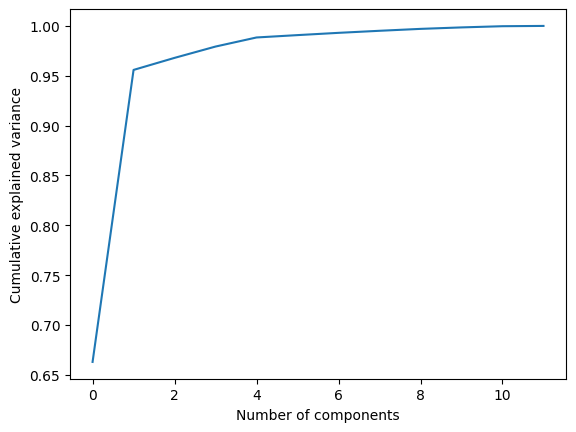

In [81]:
# Plotting the needed components 
pca = PCA().fit(X) 
plt.plot(np.cumsum(pca.explained_variance_ratio_)) 
plt.xlabel('Number of components') 
plt.ylabel('Cumulative explained variance'); 

### KNeigborsClassifier


In [105]:
 #Create KNN Classifier
kNN = KNeighborsClassifier(n_neighbors = 4) #t 4 neighbors, there is no point in testing with more n-neigh... 
##Because the accuracy is nearly the same

# Train the model using the training sets
kNN.fit(X_train, y_train)

# Predict the response for test dataset
y_pred = kNN.predict(X_test)

In [106]:
# Model accuracy 
print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred)) )

Accuracy: 0.67


In [107]:
# Display the classification report
print(classification_report(y_test, y_predict))

              precision    recall  f1-score   support

         0.0       0.38      0.27      0.32        22
         1.0       0.41      0.41      0.41        49
         2.0       0.51      0.49      0.50        85
         3.0       0.52      0.50      0.51        86
         4.0       0.85      0.89      0.87       237

    accuracy                           0.67       479
   macro avg       0.53      0.51      0.52       479
weighted avg       0.66      0.67      0.67       479



###  Unsupervised ML Algorithms

#### k-means clustering

In [111]:
from sklearn.preprocessing import StandardScaler

# Create an object using Standard scalscaler
scaler = StandardScaler()

# Train the StandardScaler model
scaler.fit(X_train)

# transform data
X_train_scaled = scaler.transform(X_train)
X_test_scaled  = scaler.transform(X_test)
X_scaled = scaler.transform(X)

# print dataset after scaling
print(X_train_scaled, '\t', X_test_scaled, '\t', X_scaled)

[[ 1.37285117  0.97165101  2.26211643 ... -0.49705784 -0.43041146
  -0.55096019]
 [-0.40585814  0.97165101  0.23853507 ... -0.49705784  2.3233582
  -1.25109413]
 [ 0.48349652 -1.0291761   1.25032575 ... -0.49705784 -0.43041146
  -1.92618913]
 ...
 [-0.40585814  0.97165101  0.23853507 ... -0.49705784 -0.43041146
   0.16457584]
 [ 1.37285117 -1.0291761   0.23853507 ... -0.49705784 -0.43041146
  -0.60256052]
 [ 1.37285117 -1.0291761   0.23853507 ... -0.49705784 -0.43041146
  -2.06162881]] 	 [[-1.29521279  0.97165101  2.26211643 ...  2.01183831  2.3233582
  -0.51664154]
 [-0.40585814  0.97165101  2.26211643 ... -0.49705784  2.3233582
   1.3273431 ]
 [-1.29521279 -1.0291761  -1.78504629 ... -0.49705784  2.3233582
   0.14913268]
 ...
 [ 0.48349652 -1.0291761  -0.77325561 ... -0.49705784 -0.43041146
   0.47083302]
 [ 1.37285117  0.97165101 -1.78504629 ... -0.49705784 -0.43041146
   0.95695117]
 [ 1.37285117  0.97165101 -1.78504629 ... -0.49705784 -0.43041146
  -1.13236061]] 	 [[ 0.48349652  0

In [117]:
# keep the first two principal components of the data
pca = PCA(4) #n_components = 4 is the highest variation, the most important

# transform data into the first two principal components
X_pca = pca.fit_transform(X_scaled)

print("Original shape: {}".format(str(X_scaled.shape)))
print("Reduced shape: {}".format(str(X_pca.shape)))

Original shape: (2392, 12)
Reduced shape: (2392, 4)


In [118]:
print(pca.explained_variance_ratio_)

[0.16443449 0.09320325 0.08928947 0.08655283]


In [120]:
total_var = pca.explained_variance_ratio_.sum() * 100
print(X_pca, total_var)

[[ 1.7924002   0.85017328  1.79223395  0.83986387]
 [ 1.89970108  0.12223974 -0.13325204 -1.3637611 ]
 [-2.63667808 -0.36250884 -0.70267225  0.77521286]
 ...
 [-1.29159074  1.36748377 -0.99294892 -0.45218089]
 [-0.14849789 -0.06410055  1.14587019  0.42203482]
 [ 0.27030133  1.31672914 -0.25000993 -0.17078993]] 43.34800472688087


In [126]:
#pip install mglearn
import mglearn 

Text(0, 0.5, 'Second principal component')

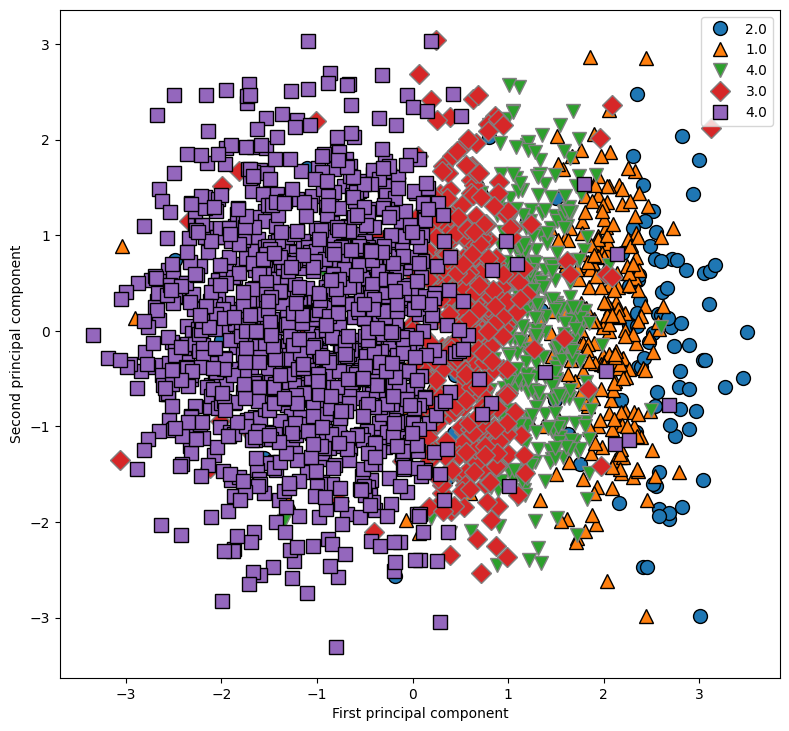

In [141]:
# plot first vs. second principal component, colored by class
plt.figure(figsize = (8, 8), layout = 'tight')
mglearn.discrete_scatter(X_pca[:, 0], X_pca[:, 1], target.GradeClass)
plt.legend(target.GradeClass, loc="best")
plt.gca().set_aspect("equal")
plt.xlabel("First principal component")
plt.ylabel("Second principal component")